**Import Libraries**

In [ ]:
# Import libraries used across the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

**Task 1: Load dataset and Check for Missing values**

In [ ]:
# Load dataset
df = pd.read_csv("loan_data.csv")

# Check number of missing values per column
df.isnull().sum()

,0
person_age,0
person_gender,0
person_education,0
person_income,0
person_emp_exp,0
person_home_ownership,0
loan_amnt,0
loan_intent,0
loan_int_rate,0
loan_percent_income,0


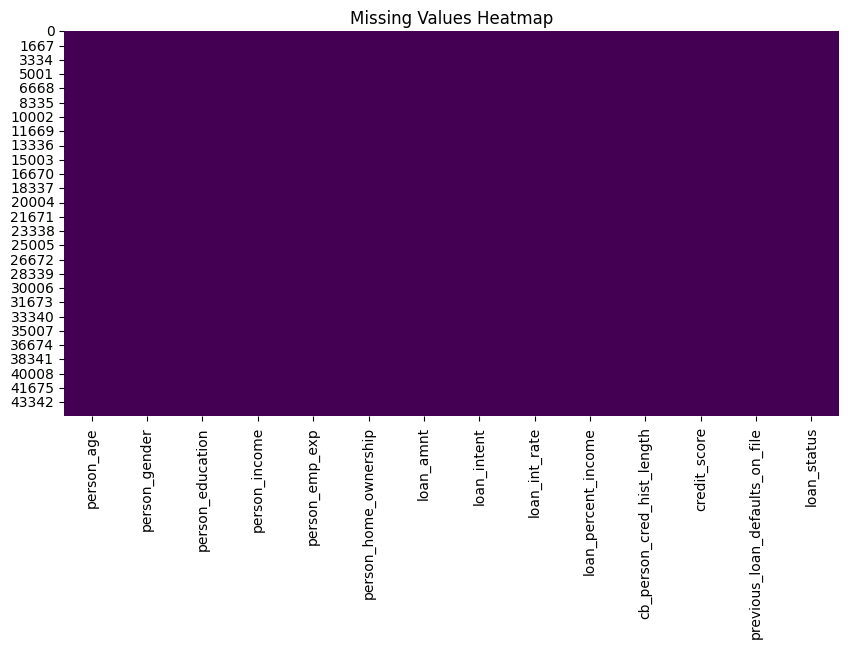

In [ ]:
# heatmap to Visualize missing values
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

**Task 2: Outlier Detection & Removal**

* We focused on person_income because it has the largest range and potential extreme values, which can skew the model.

* loan_amnt and loan_int_rate may be large ranges, but extreme values are rarer or already cut off by the bank’s rules.

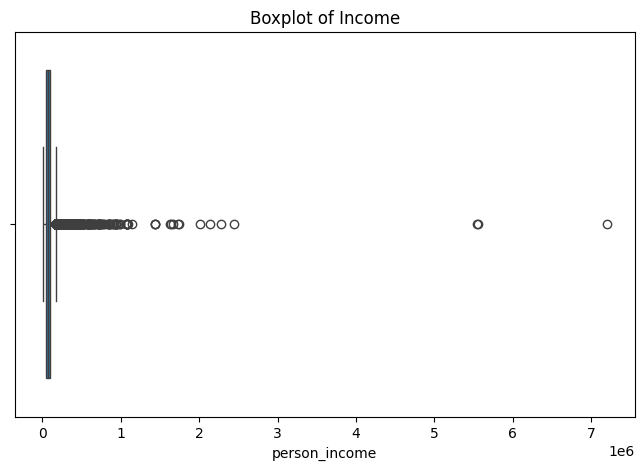

In [ ]:
# 1. Visualize outliers with boxplot
plt.figure(figsize=(8,5))
sns.boxplot(x=df['person_income'])
plt.title("Boxplot of Income")
plt.show()

In [ ]:
# 2. Use IQR method to detect outliers in person_income
Q1 = df['person_income'].quantile(0.25)
Q3 = df['person_income'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -25673.875
Upper Bound: 168667.125


In [ ]:
# 3. Remove outliers
df_clean = df[(df['person_income'] >= lower_bound) & (df['person_income'] <= upper_bound)].copy()

In [ ]:
print("Original shape:", df.shape)
print("After outlier removal:", df_clean.shape)

Original shape: (45000, 14)
After outlier removal: (42782, 14)


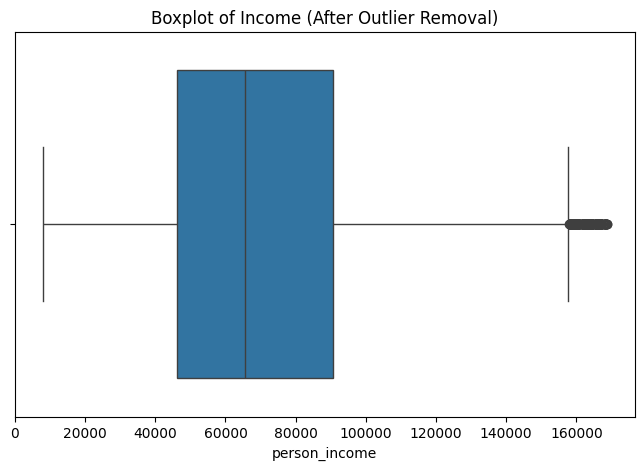

In [ ]:
# After removing outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df_clean['person_income'])
plt.title("Boxplot of Income (After Outlier Removal)")
plt.show()